In [11]:
import sys
sys.path.append("..")

from project1.data import load_data, EMOTIONS
from collections import Counter, OrderedDict
import part1
from project1 import encoders, experiments
import numpy as np

In [2]:
# loading data and print data info

dataset, outcome_space = load_data(test_size=0.2, seed=0)

train_texts  = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
pairs  = list(zip(train_texts, train_labels))   

print(dataset)                              
print("example sentence:" , dataset["train"][0])                   
print("class id and their counts:", Counter(dataset["train"]["label"]))   
print("outcome space:", [outcome_space.name(i) for i in range(len(EMOTIONS))]) 
print("first 20 (text, label) pairs:", pairs[0:20])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 6012
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1504
    })
})
example sentence: {'text': 'Grovelling people.', 'label': 4}
class id and their counts: Counter({0: 877, 1: 868, 5: 863, 3: 858, 6: 853, 2: 848, 4: 845})
outcome space: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
first 20 (text, label) pairs: [('Grovelling people.', 4), ('My sweatheart were away on a trip, and then she got problems.', 3), ('When a close friend, residing in the hostel, lost his father I  \nreally pittied him and the situation made me feel sad.', 3), ('Receiving a postcard form my sweetheart who was abroad on  \nvacation, not being at all sure if he would write me or not.', 0), ('When my father made my mother go through really terrible  \nsituations, I felt furious, impotent, nervous, upset, ........', 2), ('When I realized that I was far behind the others in th

In [3]:
# implement tokenizer and encoders
tokenizer = part1.experiment.train_tokenizer(
  train_texts,
  vocab_size=3000,
  min_frequency=2
)

In [4]:
# encoder representations
representations = {
  "indicator": encoders.TokenIndicator(tokenizer),
  "bow": encoders.BagOfWords(tokenizer)
  # need a third
}

# classification architectures
architectures = {
    "logistic": dict(model_option="logistic", loglin_args={"max_iter": 200}),
    "mlp":      dict(model_option="mlp", smlp_args={"hidden_dim": 128, "num_epochs": 20})
    # need a third
}

  0%|          | 0/5 [00:00<?, ?it/s]

/home/klaas/courses/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/klaas/courses/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/klaas/courses/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/klaas/courses/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/hom

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 4.941 seconds
Dataloader done! Time taken: 0.267 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

/home/klaas/projects/nlp_projects/nlp1-project/notebooks/../part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/klaas/projects/nlp_projects/nlp1-project/notebooks/../part1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


... (19 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8642 | train acc: 0.3139 | val loss: 1.7303 | val acc: 0.4384
Epoch 02 | train loss: 1.4270 | train acc: 0.5956 | val loss: 1.4237 | val acc: 0.5158
Epoch 03 | train loss: 0.9832 | train acc: 0.7266 | val loss: 1.3065 | val acc: 0.5424
Epoch 04 | train loss: 0.7013 | train acc: 0.8166 | val loss: 1.2981 | val acc: 0.5582
Epoch 05 | train loss: 0.5298 | train acc: 0.8694 | val loss: 1.3339 | val acc: 0.5566
Epoch 06 | train loss: 0.4039 | train acc: 0.9083 | val loss: 1.4035 | val acc: 0.5499
Epoch 07 | train loss: 0.3105 | train acc: 0.9351 | val loss: 1.4751 | val acc: 0.5541
Epoch 08 | train loss: 0.2435 | train acc: 0.9549 | val loss: 1.5620 | val acc: 0.5532
Epoch 09 | train loss: 0.1928 | train acc: 0.9705 | val loss: 1.6491 | val acc: 0.5574
Epoch 10 | train loss: 0.1534 | train acc: 0.9775 | val loss: 1.7271 | val acc: 0.5582
Epoch 11 | train loss: 0.1274 | train acc: 0.9827 | val loss: 1.8095 | val acc: 0.5532
Epoch 12 | train loss: 0.1041 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8703 | train acc: 0.3189 | val loss: 1.7390 | val acc: 0.4700
Epoch 02 | train loss: 1.4145 | train acc: 0.6206 | val loss: 1.4427 | val acc: 0.5275
Epoch 03 | train loss: 0.9598 | train acc: 0.7301 | val loss: 1.3123 | val acc: 0.5449
Epoch 04 | train loss: 0.6839 | train acc: 0.8187 | val loss: 1.3046 | val acc: 0.5557
Epoch 05 | train loss: 0.5101 | train acc: 0.8728 | val loss: 1.3521 | val acc: 0.5399
Epoch 06 | train loss: 0.3835 | train acc: 0.9170 | val loss: 1.4086 | val acc: 0.5308
Epoch 07 | train loss: 0.2947 | train acc: 0.9407 | val loss: 1.4956 | val acc: 0.5275
Epoch 08 | train loss: 0.2291 | train acc: 0.9597 | val loss: 1.5787 | val acc: 0.5308
Epoch 09 | train loss: 0.1836 | train acc: 0.9717 | val loss: 1.6552 | val acc: 0.5183
Epoch 10 | train loss: 0.1466 | train acc: 0.9788 | val loss: 1.7423 | val acc: 0.5216
Epoch 11 | train loss: 0.1185 | train acc: 0.9848 | val loss: 1.8174 | val acc: 0.5166
Epoch 12 | train loss: 0.0981 | train acc: 

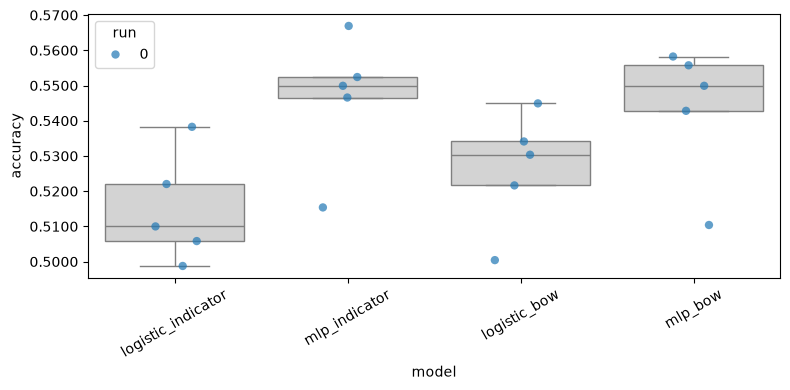

In [5]:
# run experiments on all combinations of representations and architectures

## MLP currently overfitting -> need some regularization
my_classifiers = experiments.run_experiments(representations, architectures, pairs, outcome_space)

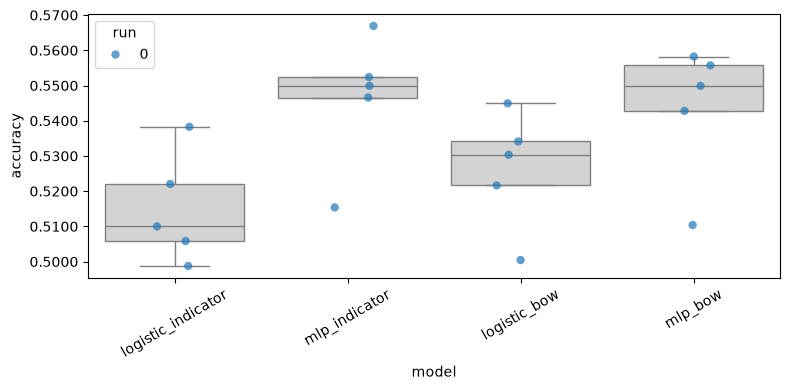

In [9]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

A=logistic_indicator B=mlp_indicator: P(A wins)=0.0240 P(Tie)=0.0594 P(B wins)=0.9166 Effect Size=2.25


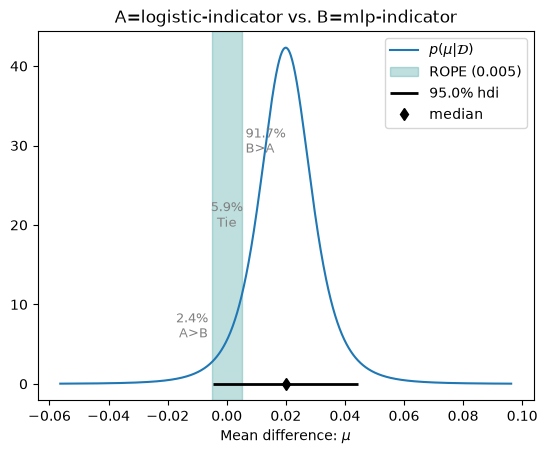

In [ ]:

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator')

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_bow').flatten(),  # [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'mlp_indicator').flatten(),  # [num_runs * num_folds]
    names=["logistic-indicator", "mlp-indicator"]
)
p_a, p_tie, p_b = posterior.probs(0.005) # rope = 0.5%
print(f"A=logistic_indicator B=mlp_indicator: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
# if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)
_ = posterior.plot(0.005)  